# Génération de QCM avec validation automatique
**TALN — Sujet 11 — Filière IA & Science des Données, 5e année — EMSI Rabat — 2026/2027**

## Objectif
Le système lit un **support de cours** et produit des **questions à choix multiples (QCM)** : une question, **une** bonne réponse et **trois distracteurs** plausibles mais faux.
Les modèles de langage produisent des QCM rapidement, mais souvent défectueux : question sans réponse dans le cours, deux bonnes réponses, distracteur en réalité vrai…
Le cœur du projet est donc un **validateur automatique**, qui rejette les QCM défectueux, et la **mesure de ce qu'il apporte**.

## Plan du notebook
| Étape | Contenu |
|---|---|
| 0 | Configuration, reproductibilité |
| 1 | Collecte des 6 supports de cours (langage C) |
| 2 | Extraction et nettoyage du texte |
| 3 | Découpage en passages |
| 4 | Base de référence : questions à trous + distracteurs par embeddings |
| 5 | Modèle avancé : **LLM ouvert** (prompt few-shot, sortie JSON) |
| 6 | Contrôles de forme |
| 7 | Validateur : V1 répondabilité, V2 bonne réponse unique, V3 distracteurs faux |
| 8 | Filtrage et mesure de l'apport du filtre |
| 9 | Évaluation humaine (60 QCM) et accord entre évaluateurs |
| 10 | Ablations et sensibilité |
| 11 | Analyse des erreurs, limites, éthique |

## Choix du modèle avancé : un LLM ouvert plutôt qu'un modèle seq2seq fine-tuné
L'énoncé laisse le choix entre « un modèle de langage ou un modèle fine-tuné ». Nous retenons un **LLM ouvert instruit** (par exemple Qwen2.5-7B-Instruct, quantifié en 4 bits pour tenir sur le GPU de Colab), pour quatre raisons :
1. **Il produit tout le QCM.** Un modèle seq2seq (mT5, BARThez) fine-tuné sur FQuAD ou PIAF apprend seulement à produire une *question* à partir d'une réponse. Ces jeux de données ne contiennent **pas de distracteurs**, il faudrait donc un second système pour les créer. Le LLM génère question, bonne réponse et distracteurs en un seul appel.
2. **Pas de données d'entraînement de QCM en français.** Il n'existe pas de grand corpus public de QCM annotés en français. Le LLM fonctionne en *few-shot* : quelques exemples dans le prompt suffisent.
3. **Meilleurs distracteurs.** Un bon distracteur exige de comprendre le sens (une notion voisine mais fausse). Un LLM le fait bien mieux qu'un petit modèle seq2seq.
4. **Faisable sur Colab.** Un modèle d'environ 7 milliards de paramètres quantifié en 4 bits occupe environ 5 Go de mémoire GPU (une T4 en a 15).

Contrepartie assumée : un LLM **hallucine** parfois (fausse bonne réponse, distracteur vrai). C'est précisément ce que le validateur de l'étape 7 doit détecter, ce qui rend le volet avancé indispensable.

---
# Étape 0 — Configuration et reproductibilité

**À quoi sert cette étape ?**
- Installer les bibliothèques manquantes (sur Colab).
- Définir **en un seul endroit** tous les chemins et hyperparamètres du projet (dictionnaire `CONFIG`). Pour une ablation, on modifie une valeur ici sans chercher dans tout le notebook.
- **Fixer les graines aléatoires.** Le barème exige des résultats reproductibles : deux exécutions doivent donner les mêmes passages, le même échantillonnage et les mêmes QCM.

**Pourquoi ces choix ?**
- On fixe les graines de `random`, `numpy` **et** `torch`. Chaque bibliothèque a son propre générateur aléatoire : fixer seulement `random` laisserait `torch` (utilisé par le LLM) non déterministe.
- On utilise `pathlib.Path` plutôt que des chaînes de caractères. Les chemins fonctionnent alors pareil sous Windows, Linux et Colab.

In [1]:
# Installation des dépendances absentes de Colab (sans effet si elles sont déjà installées)
import importlib.util, subprocess, sys
for pkg in ["pdfplumber"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

In [2]:
import os, re, json, random, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

# --- Racine du dépôt : le notebook peut être lancé depuis notebooks/ ou depuis la racine ---
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CONFIG = {
    "seed": 42,
    # Chemins
    "raw_dir":       ROOT / "data" / "raw",
    "processed_dir": ROOT / "data" / "processed",
    "annot_dir":     ROOT / "data" / "annotations",
    "qcm_dir":       ROOT / "outputs" / "qcm",
    "fig_dir":       ROOT / "outputs" / "figures",
    # Découpage en passages (étape 3)
    "chunk_min_words": 150,
    "chunk_max_words": 300,
    "chunk_drop_below": 60,      # un reste de moins de 60 mots est trop pauvre pour une question
    # Tokenizer du futur modèle de questions-réponses du validateur
    "qa_tokenizer": "almanach/camembert-base",
    "qa_max_tokens": 512,
}
for k, v in CONFIG.items():
    if k.endswith("_dir"):
        v.mkdir(parents=True, exist_ok=True)

def set_seed(seed: int) -> None:
    # Fixe toutes les sources d'aléa utilisées dans le projet.
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass

set_seed(CONFIG["seed"])

# Versions affichées dans le notebook pour la reproductibilité
print("Racine du projet :", ROOT)
print("Python :", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)
try:
    import torch
    print("torch", torch.__version__, "| GPU disponible :", torch.cuda.is_available())
except ImportError:
    print("torch non installé")

Racine du projet : C:\Users\douae\talnprj
Python : 3.11.9 | pandas 3.1.0 | numpy 2.4.6
torch 2.13.0+cpu | GPU disponible : False


---
# Étape 1 — Collecte des supports de cours

**À quoi sert cette étape ?** L'énoncé exige **au moins cinq supports de cours publics ou fournis par l'enseignant**. Ce sont le texte d'entrée du générateur et la référence du validateur : un QCM n'est valide que s'il est répondable **à partir de ce texte**.

**Notre corpus : 6 supports de cours PDF sur la programmation en langage C**, écrits par 6 auteurs ou établissements différents.

| id | Fichier | Titre | Auteur / établissement | Format |
|---|---|---|---|---|
| C1 | `cours.pdf` | Programmation en langage C | Anne Canteaut (INRIA) | polycopié LaTeX |
| C2 | `LelangageC_rgww.pdf` | Le langage C | Patrick Trau | polycopié |
| C3 | `cours_programmation_c.pdf` | Programmation C | M. E. Elhdhili, H. Boucetta | polycopié Word |
| C4 | `annexe_08_2_cours_programmation en langage C.pdf` | Programmation en langage C | M. Qbadou (ENSET Mohammedia), 2022/2023 | polycopié Word |
| C5 | `coursC.pdf` | Initiation au langage C | auteur non indiqué | polycopié LaTeX |
| C6 | `support-C-JacquelinCharbonnel.pdf` | Cours de langage C | Jacquelin Charbonnel (CNRS) | diapositives |

**Pourquoi un seul sujet (le langage C) et 6 auteurs, plutôt que 6 matières différentes ?**
- **Cas d'usage réaliste.** Un enseignant veut des QCM sur **sa** matière. Le corpus correspond à ce scénario.
- **Une même notion, plusieurs rédactions.** Les pointeurs, les boucles ou les opérateurs sont expliqués 6 fois, avec des styles différents. On pourra vérifier si la qualité des QCM dépend du **style de rédaction** (polycopié détaillé contre diapositives télégraphiques) plutôt que du contenu.
- **Vocabulaire technique.** Le C mêle français et termes de code (`int`, `printf`, `malloc`). C'est un vrai défi pour le générateur, et surtout pour le validateur, dont les modèles sont entraînés sur du français général.
- **Plusieurs formats PDF** (LaTeX, Word, diapositives). Le nettoyage de l'étape 2 doit être robuste, et cette difficulté est documentée.

**Droits d'auteur.** Ces supports sont accessibles publiquement, mais leurs auteurs en gardent les droits. On les cite dans `sources.csv` et dans l'article, et on **ne redistribue pas les PDF** : ils sont exclus du dépôt GitHub par `.gitignore`. Pour exécuter le notebook, on dépose les PDF dans `data/raw/`. Sur Colab, la cellule ci-dessous propose de les téléverser s'ils manquent.

**Données personnelles.** Deux PDF contiennent l'adresse e-mail de leur auteur. Ces adresses sont supprimées à l'étape 2. Seuls les noms des auteurs sont conservés, car ils sont nécessaires pour citer les sources.

In [3]:
COURS = [
    {"id": "C1", "fichier": "cours.pdf",                   "titre": "Programmation en langage C",
     "auteur": "Anne Canteaut (INRIA)",                    "format": "polycopié LaTeX"},
    {"id": "C2", "fichier": "LelangageC_rgww.pdf",         "titre": "Le langage C",
     "auteur": "Patrick Trau",                             "format": "polycopié"},
    {"id": "C3", "fichier": "cours_programmation_c.pdf",   "titre": "Programmation C",
     "auteur": "M. E. Elhdhili, H. Boucetta",              "format": "polycopié Word"},
    {"id": "C4", "fichier": "annexe_08_2_cours_programmation en langage C.pdf",
     "titre": "Programmation en langage C",
     "auteur": "M. Qbadou (ENSET Mohammedia), 2022/2023",  "format": "polycopié Word"},
    {"id": "C5", "fichier": "coursC.pdf",                  "titre": "Initiation au langage C",
     "auteur": "non indiqué",                              "format": "polycopié LaTeX"},
    {"id": "C6", "fichier": "support-C-JacquelinCharbonnel.pdf", "titre": "Cours de langage C",
     "auteur": "Jacquelin Charbonnel (CNRS)",              "format": "diapositives"},
]

manquants = [c["fichier"] for c in COURS if not (CONFIG["raw_dir"] / c["fichier"]).exists()]
if manquants:
    try:                                   # Sur Colab : téléversement des PDF manquants
        from google.colab import files
        print("PDF manquants, à téléverser :", manquants)
        for nom, contenu in files.upload().items():
            (CONFIG["raw_dir"] / nom).write_bytes(contenu)
    except ImportError:
        raise FileNotFoundError(f"Déposer ces PDF dans {CONFIG['raw_dir']} : {manquants}")

import pdfplumber
for c in COURS:
    with pdfplumber.open(CONFIG["raw_dir"] / c["fichier"]) as pdf:
        c["n_pages"] = len(pdf.pages)
    c["taille_Ko"] = round((CONFIG["raw_dir"] / c["fichier"]).stat().st_size / 1024)
    c["licence"] = "droits réservés à l'auteur — usage pédagogique, non redistribué"

sources = pd.DataFrame(COURS)
assert len(sources) >= 5, "L'énoncé exige au moins 5 supports de cours."
sources[["id", "titre", "auteur", "format", "n_pages", "taille_Ko"]]

,id,titre,auteur,format,n_pages,taille_Ko
0,C1,Programmation en langage C,Anne Canteaut (INRIA),polycopié LaTeX,133,432
1,C2,Le langage C,Patrick Trau,polycopié,71,336
2,C3,Programmation C,"M. E. Elhdhili, H. Boucetta",polycopié Word,76,724
3,C4,Programmation en langage C,"M. Qbadou (ENSET Mohammedia), 2022/2023",polycopié Word,68,1379
4,C5,Initiation au langage C,non indiqué,polycopié LaTeX,52,287
5,C6,Cours de langage C,Jacquelin Charbonnel (CNRS),diapositives,60,635


---
# Étape 2 — Extraction et nettoyage du texte

**À quoi sert cette étape ?** Transformer chaque PDF en **texte propre, découpé par section**. Le texte extrait brut d'un PDF contient beaucoup d'éléments inutiles, voire nuisibles, pour générer des questions. Nous les avons repérés en lisant l'extraction brute des 6 cours :

| Problème observé | Exemple | Traitement |
|---|---|---|
| Accents LaTeX détachés (C1, C5) | `´et´e`, `con¸cu`, `syst`eme` | Recollage de l'accent sur sa voyelle, puis normalisation Unicode |
| Espaces manquants (C5) | `Lefichiersourcecontient…` | Tolérance d'espacement de `pdfplumber` réduite (`x_tolerance=1.5`) |
| Ligatures typographiques | `aﬁn` (ﬁ = 1 caractère) | Normalisation Unicode NFKC → `afin` |
| Table des matières | `1.4 Les types ........ 13` | Ligne supprimée si elle contient des points de conduite |
| En-têtes et pieds de page | `Le langage C − cours P.TRAU`, `1.3. Présentation du langage 9` | Ligne en haut ou en bas de page répétée sur plusieurs pages, ou titre suivi d'un numéro de page |
| **Code source** | `int main() {`, `printf("%d", x);` | Ligne supprimée (voir ci-dessous) |
| Sections non pédagogiques | Exercices, corrigés, index, bibliographie | Section entière supprimée |
| Mots coupés en fin de ligne | `préproces-\nseur` | Recollés |
| Adresses e-mail, URL | adresse d'un auteur | Supprimées (données personnelles) |

On **conserve le titre de section** de chaque bloc de texte. Il sert à l'étape 3 (on ne découpe pas à travers deux sections) puis à l'analyse des erreurs (quelles sections produisent de mauvais QCM ?).

**Pourquoi supprimer le code source ?** C'est le choix le plus discutable, alors justifions-le :
1. Le **validateur** repose sur un modèle de questions-réponses et un modèle d'inférence (NLI) entraînés sur du **français en prose**. Ils ne savent pas vérifier une question du type « que affiche ce programme ? », qui demande d'*exécuter* mentalement le code.
2. Une fois aplati en texte par l'extraction PDF, le code perd son indentation et ses retours à la ligne. Il devient illisible pour le générateur.
3. Les **notions** (rôle de `printf`, différence entre `while` et `do…while`, arithmétique des pointeurs) restent expliquées **en prose** autour du code. Les mots-clés cités dans une phrase sont donc conservés.

*Limite assumée* : on ne génère pas de QCM de lecture de code. Ce point sera discuté dans l'article. Ce serait une extension possible, avec un validateur qui exécute le code.

**Pourquoi des règles et pas un modèle pour nettoyer ?** Les défauts sont **réguliers et identifiés** (motifs d'accents, points de conduite, syntaxe du C). Des règles sont transparentes, rapides, et on **compte** ce que chacune supprime (tableau plus bas). Un modèle pourrait supprimer du contenu utile sans qu'on le voie.

**Pourquoi `pdfplumber` plutôt que PyMuPDF ?** Nous avons comparé les deux. PyMuPDF sépare les numéros de section de leur titre (`1.1` puis `Historique` sur deux lignes), ce qui empêche de repérer les sections. `pdfplumber` garde `1.1 Historique` sur une ligne et permet de régler l'espacement entre les mots.

In [4]:
import unicodedata
from collections import Counter

# ---------- 1. Réparation des accents LaTeX : "´et´e" -> "été" ----------
ACCENT_COMBINANT = {"´": "\u0301", "`": "\u0300", "ˆ": "\u0302", "¨": "\u0308", "˜": "\u0303"}
VOYELLES = "aeiouyAEIOUYı"

def reparer_accents(t: str) -> str:
    t = re.sub(r"¸\s?([cC])", "\\1\u0327", t)          # cédille avant le c : "con¸cu"
    t = re.sub(r"([cC])¸", "\\1\u0327", t)             # cédille après le c : "plac¸ons"
    # accent placé AVANT sa voyelle : "´e" -> "é"
    t = re.sub(r"([´`ˆ¨˜])\s?([" + VOYELLES + r"])", lambda m: m.group(2) + ACCENT_COMBINANT[m.group(1)], t)
    # accent restant, placé APRÈS sa voyelle : "Pre´sentation", "ou`" -> "é", "ù"
    t = re.sub(r"([" + VOYELLES + r"])([´`ˆ¨˜])", lambda m: m.group(1) + ACCENT_COMBINANT[m.group(2)], t)
    t = t.replace("ı\u0302", "î").replace("ı\u0308", "ï").replace("ı", "i")
    # NFC fusionne lettre + accent combinant ; NFKC remplace les ligatures ("ﬁ" -> "fi")
    return unicodedata.normalize("NFKC", unicodedata.normalize("NFC", t))

# ---------- 2. Règles de repérage des lignes ----------
RE_SOMMAIRE = re.compile(r"(\.\s?){4,}|…{2,}")
RE_CODE = re.compile(r"^\s*(\d+\s+)?(#\s*(include|define|if|endif|else)|int\s|char\s|float\s|double\s|void\s"
                     r"|long\s|struct\s|typedef\s|return\b|printf\s*\(|scanf\s*\(|for\s*\(|while\s*\(|if\s*\("
                     r"|else\b|switch\s*\(|case\s|[{}])")
SYMBOLES_CODE = set("{}();=<>[]#&|%*")

def est_code(l: str) -> bool:
    # Ligne de code C : commence par un mot-clé ou une accolade, finit par ; { }, ou est riche en symboles
    if RE_CODE.match(l) or l.rstrip().endswith((";", "{", "}")):
        return True
    return sum(c in SYMBOLES_CODE for c in l) / max(len(l), 1) > 0.08

RE_TITRE = re.compile(r"^(CHAPITRE|Chapitre)\s+\d+\b.*$|^(\d{1,2}(\.\d{1,2}){0,3})\.?\s+([A-ZÀÂÉÈÊÎÔÛÇ].{2,80})$")

def titre_de(l: str):
    # Renvoie le titre si la ligne est un titre numéroté ("1.2 La compilation", "CHAPITRE 3 : …")
    m = RE_TITRE.match(l)
    if not m or len(l.split()) > 10 or l.rstrip().endswith((",", "-", ";", ".")):
        return None
    return l.strip()

RE_EXCLURE = re.compile(r"\b(exercices?|corrections?|corrigés?|solutions?|bibliographie|index|annexes?|"
                        r"sommaire|table des matières|références|travaux pratiques|objectifs pédagogiques)\b")
RE_PERSO = re.compile(r"\S+@\S+|https?://\S+|www\.\S+")

def nettoyer_pdf(chemin: Path, x_tol: float = 1.5):
    # Renvoie (liste de {section, texte}, compteur de lignes par traitement, nb de mots bruts)
    with pdfplumber.open(chemin) as pdf:
        pages = [reparer_accents(p.extract_text(x_tolerance=x_tol) or "").splitlines() for p in pdf.pages]
    pages = [[l.strip() for l in p if l.strip()] for p in pages]
    n_mots_brut = sum(len(l.split()) for p in pages for l in p)

    # En-têtes / pieds : lignes des bords de page qui reviennent sur ≥ 3 pages (chiffres ignorés)
    cle = lambda l: re.sub(r"\d+", "#", l)
    bords = Counter(cle(l) for p in pages for l in set(p[:2] + p[-2:]))
    repetes = {k for k, n in bords.items() if n >= 3}

    stats, flux, section, exclure = Counter(), {}, "Début", False
    for p in pages:
        for i, l in enumerate(p):
            au_bord = i < 2 or i >= len(p) - 2
            if au_bord and (cle(l) in repetes or re.fullmatch(r"[\d\s\-–/]+", l)
                            or (titre_de(l) and re.search(r"\s\d{1,3}$", l))):
                stats["en-tête / pied de page"] += 1; continue
            if RE_SOMMAIRE.search(l):
                stats["table des matières"] += 1; continue
            t = titre_de(l)
            if t:
                nom = re.sub(r"^(CHAPITRE|Chapitre)?\s*[\d.]*\s*:?\s*", "", t).strip(" :") or t
                exclure = bool(RE_EXCLURE.search(nom.lower()))
                section = nom
                stats["titre de section"] += 1; continue
            if exclure:
                stats["section exclue"] += 1; continue
            if est_code(l):
                stats["code source"] += 1; continue
            flux.setdefault(section, []).append(RE_PERSO.sub("", l))
            stats["conservée"] += 1

    paragraphes = []
    for s, lignes in flux.items():
        texte = "\n".join(lignes)
        texte = re.sub(r"(\w)-\n(\w)", r"\1\2", texte)      # mots coupés en fin de ligne
        texte = re.sub(r"\s*\n\s*", " ", texte)             # une section = un texte continu
        texte = re.sub(r"\s+", " ", texte).strip()
        texte = re.sub(r"\s+([,.;:!?)])", r"\1", texte)
        if len(texte.split()) >= 30:                        # section quasi vide (titre seul) : ignorée
            paragraphes.append({"section": s, "texte": texte})
    return paragraphes, stats, n_mots_brut

corpus, stats_lignes = {}, {}
for c in COURS:
    corpus[c["id"]], stats_lignes[c["id"]], c["n_mots_brut"] = nettoyer_pdf(CONFIG["raw_dir"] / c["fichier"])

sources = pd.DataFrame(COURS)
sources["n_mots_nettoye"] = [sum(len(p["texte"].split()) for p in corpus[i]) for i in sources["id"]]
sources["n_sections"] = [len(corpus[i]) for i in sources["id"]]
sources["%_retire"] = (100 * (1 - sources["n_mots_nettoye"] / sources["n_mots_brut"])).round(1)
sources.to_csv(CONFIG["raw_dir"] / "sources.csv", index=False)

# Sauvegarde du texte nettoyé (traçabilité : on peut relire ce que le modèle a reçu)
with open(CONFIG["processed_dir"] / "corpus_nettoye.jsonl", "w", encoding="utf-8") as f:
    for cid, pars in corpus.items():
        for p in pars:
            f.write(json.dumps({"cours_id": cid, **p}, ensure_ascii=False) + "\n")

sources[["id", "titre", "format", "n_pages", "n_mots_brut", "n_mots_nettoye", "%_retire", "n_sections"]]

,id,titre,format,n_pages,n_mots_brut,n_mots_nettoye,%_retire,n_sections
0,C1,Programmation en langage C,polycopié LaTeX,133,36361,24816,31.8,87
1,C2,Le langage C,polycopié,71,20292,13033,35.8,58
2,C3,Programmation C,polycopié Word,76,21115,13896,34.2,103
3,C4,Programmation en langage C,polycopié Word,68,11764,6053,48.5,66
4,C5,Initiation au langage C,polycopié LaTeX,52,14726,8516,42.2,58
5,C6,Cours de langage C,diapositives,60,10126,4250,58.0,43


**Que supprime chaque règle ?** On compte, pour chaque cours, le nombre de lignes traitées par chaque règle. Ce graphique justifie le nettoyage dans l'article et révèle les différences de format. Par exemple, les diapositives (C6) et le polycopié de C4 sont très riches en code.

,conservée,code source,section exclue,table des matières,en-tête / pied de page,titre de section
C1,2941,1646,4,141,172,110
C2,1033,536,1073,104,130,67
C3,1515,863,0,154,157,136
C4,761,969,25,93,147,106
C5,825,473,6,74,71,84
C6,600,691,39,94,128,81


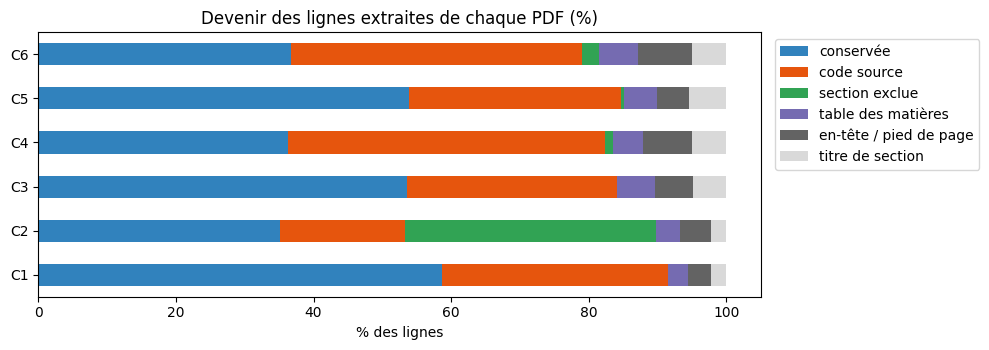

In [5]:
df_lignes = pd.DataFrame(stats_lignes).T.fillna(0).astype(int)
ordre_cols = ["conservée", "code source", "section exclue", "table des matières",
              "en-tête / pied de page", "titre de section"]
df_lignes = df_lignes[[c for c in ordre_cols if c in df_lignes.columns]]
display(df_lignes)

(df_lignes.div(df_lignes.sum(axis=1), axis=0) * 100).plot.barh(
    stacked=True, figsize=(10, 3.6), colormap="tab20c",
    title="Devenir des lignes extraites de chaque PDF (%)")
plt.xlabel("% des lignes"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.savefig(CONFIG["fig_dir"] / "nettoyage_lignes.png", dpi=150); plt.show()

**Vérification visuelle.** On affiche les sections retenues pour un cours et un extrait de texte nettoyé. On contrôle ainsi que les accents sont réparés (C1 est un PDF LaTeX), qu'il ne reste ni code ni sommaire, et que les titres de section ont du sens.

In [6]:
cid = "C1"
print("Sections conservées :", [p["section"] for p in corpus[cid]][:30], "…\n")
ex = next(p for p in corpus[cid] if p["section"].lower().startswith("la compilation"))
print(f"[{ex['section']}]\n{ex['texte'][:900]}")

Sections conservées : ['Historique', 'La compilation', 'Les composants élémentaires du C', 'Les identificateurs', 'Les mots-clefs', 'Les commentaires', 'Structure d’un programme C', 'Les types prédéfinis', 'Le type caractère', 'Les types entiers', 'Les types flottants', 'Les constantes', 'Les constantes entières', 'Les constantes réelles', 'Les constantes caractères', 'Les constantes chaînes de caractères', 'L’affectation', 'Les opérateurs arithmétiques', 'Les opérateurs relationnels', 'Les opérateurs logiques booléens', 'Les opérateurs logiques bit à bit', 'Les opérateurs d’affectation composée', 'Les opérateurs d’incrémentation et de décrémentation', 'L’opérateur virgule', 'L’opérateur conditionnel ternaire', 'Règles de priorité des opérateurs', 'Les instructions de branchement conditionnel', 'Branchement conditionnel if---else', 'Branchement multiple switch', 'Boucle while'] …

[La compilation]
Le C est un langage compilé (par opposition aux langages interprétés). Cela signifie qu’u

---
# Étape 3 — Découpage en passages

**À quoi sert cette étape ?** On ne donne pas un cours entier au générateur ni au validateur. On le découpe en **passages** de **150 à 300 mots**. **Chaque QCM sera généré à partir d'un seul passage et validé contre ce même passage.**

**Pourquoi découper ?**
1. **Contrainte technique du validateur.** Le modèle de questions-réponses du validateur (CamemBERT) lit au plus **512 tokens** à la fois, **question comprise**. Un passage trop long serait tronqué : la réponse pourrait se trouver dans la partie coupée et le QCM serait rejeté à tort.
2. **Validation précise.** Si on générait à partir d'un chapitre entier, il faudrait chercher *où* se trouve la réponse avant de pouvoir vérifier le QCM. Avec un passage court, on sait exactement contre quel texte vérifier.
3. **Couverture du cours.** On peut tirer des passages dans toutes les sections, ce qui évite des questions qui portent toutes sur l'introduction.

**Pourquoi 150 à 300 mots ?**
- **Moins de 150 mots** : trop peu d'information pour une question **et** trois distracteurs crédibles.
- **Plus de 300 mots** : en français, CamemBERT découpe un mot en environ 1,4 token. 300 mots font donc environ 420 tokens, ce qui laisse une marge pour la question (environ 30 tokens) sous la limite de 512. On le **vérifie** plus bas avec le vrai tokenizer.

**Pourquoi découper sur les frontières de paragraphes et de phrases, et pas tous les N mots ?** Une coupe arbitraire peut séparer une définition de son explication, ou couper une phrase en deux. On regroupe donc des **paragraphes entiers** de la même section. Un paragraphe trop long est coupé **entre deux phrases**.

**Pourquoi ne pas mélanger deux sections dans un passage ?** Un passage doit traiter d'un seul sujet. Sinon, le LLM risque de produire des questions qui croisent deux sujets, ou des distracteurs pris dans l'autre section et en réalité corrects.

**Pourquoi pas de chevauchement entre passages ?** Le chevauchement est utile en recherche documentaire (RAG). Ici, il ferait générer deux fois des questions sur les mêmes phrases, donc des QCM en double.

In [7]:
# Découpage en phrases par expression régulière : fin de phrase (. ! ?) suivie d'une majuscule.
# On n'utilise pas spaCy ici : le découpage ne sert qu'à couper les très longs paragraphes, une règle suffit.
RE_PHRASE = re.compile(r"(?<=[.!?…])\s+(?=[A-ZÀÂÉÈÊÎÔÛÇ«\"(0-9])")

def decouper_phrases(texte: str) -> list[str]:
    return [p.strip() for p in RE_PHRASE.split(texte) if p.strip()]

def decouper_en_passages(paragraphes, min_w, max_w, drop_below):
    # Regroupe des paragraphes consécutifs de la même section en passages de min_w à max_w mots.
    # 1) Unités de base : un paragraphe, ou ses phrases s'il dépasse max_w mots
    unites = []
    for p in paragraphes:
        if len(p["texte"].split()) <= max_w:
            unites.append(p)
        else:
            unites += [{"section": p["section"], "texte": ph} for ph in decouper_phrases(p["texte"])]

    passages, courant, section = [], [], None
    def n_mots(lst): return sum(len(u.split()) for u in lst)
    def fermer():
        if courant:
            passages.append({"section": section, "texte": " ".join(courant)})

    for u in unites:
        w = len(u["texte"].split())
        # On ferme le passage courant si on change de section, si l'ajout dépasserait max_w,
        # ou s'il a déjà atteint min_w (on vise des passages de taille homogène).
        if courant and (u["section"] != section or n_mots(courant) + w > max_w
                        or n_mots(courant) >= min_w):
            fermer()
            courant = []
        section = u["section"]
        courant.append(u["texte"])
    fermer()

    # Un reste trop court est fusionné avec le passage précédent de la même section si la taille
    # le permet ; sinon il est écarté (pas assez de matière pour une question et 3 distracteurs).
    resultat = []
    for p in passages:
        w = len(p["texte"].split())
        if w < drop_below:
            if resultat and resultat[-1]["section"] == p["section"] \
               and len(resultat[-1]["texte"].split()) + w <= max_w:
                resultat[-1]["texte"] += " " + p["texte"]
            continue
        resultat.append(p)
    return resultat

passages = []
for cid, pars in corpus.items():
    for k, p in enumerate(decouper_en_passages(pars, CONFIG["chunk_min_words"],
                                               CONFIG["chunk_max_words"], CONFIG["chunk_drop_below"])):
        passages.append({"passage_id": f"{cid}_{k:03d}", "cours_id": cid,
                         "section": p["section"], "texte": p["texte"],
                         "n_mots": len(p["texte"].split())})
df_pass = pd.DataFrame(passages)
print(f"{len(df_pass)} passages au total")
df_pass.groupby("cours_id")["n_mots"].describe().round(0)

443 passages au total


,count,mean,std,min,25%,50%,75%,max
cours_id,,,,,,,,
C1,140.0,171.0,84.0,60.0,137.0,165.0,185.0,916.0
C2,82.0,155.0,49.0,63.0,120.0,158.0,177.0,289.0
C3,92.0,138.0,56.0,60.0,86.0,138.0,176.0,289.0
C4,39.0,125.0,63.0,65.0,79.0,103.0,144.0,291.0
C5,58.0,137.0,53.0,69.0,96.0,130.0,166.0,279.0
C6,32.0,117.0,61.0,62.0,84.0,99.0,123.0,368.0


**Vérification de la contrainte des 512 tokens.** On compte les tokens de chaque passage avec le **vrai tokenizer de CamemBERT**, celui que le validateur utilisera. Ainsi on ne se fie pas seulement à l'estimation « 1,4 token par mot ». On réserve 40 tokens pour la question et les tokens spéciaux.

Certains passages riches en noms propres, chiffres ou termes techniques comptent plus de tokens par mot que la moyenne. Un passage qui dépasse le budget est donc **coupé en deux entre deux phrases**, puis on vérifie que plus aucun ne dépasse (`assert`). On corrige ici, avant de générer quoi que ce soit, plutôt que de laisser le validateur tronquer silencieusement le texte.

C:\Users\douae\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (532 > 512). Running this sequence through the model will result in indexing errors


Tokens par mot (moyenne) : 1.48
Passages au-delà de 472 tokens avant correction : 7 / 443
Après correction : 455 passages, tous ≤ 472 tokens (max = 463)


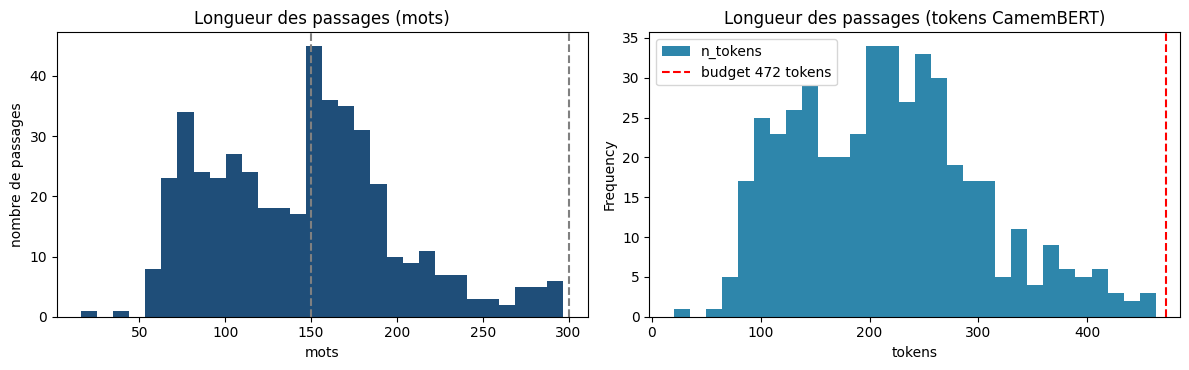

In [8]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(CONFIG["qa_tokenizer"])

budget = CONFIG["qa_max_tokens"] - 40      # 40 tokens réservés à la question et aux tokens spéciaux
def n_tok(t): return len(tok(t, add_special_tokens=False)["input_ids"])

df_pass["n_tokens"] = [n_tok(t) for t in df_pass["texte"]]
print(f"Tokens par mot (moyenne) : {(df_pass['n_tokens'] / df_pass['n_mots']).mean():.2f}")
print(f"Passages au-delà de {budget} tokens avant correction : "
      f"{(df_pass['n_tokens'] > budget).sum()} / {len(df_pass)}")

def scinder(rec):
    # Coupe un passage trop long en deux moitiés équilibrées, sur une frontière de phrase.
    if rec["n_tokens"] <= budget:
        return [rec]
    ph = decouper_phrases(rec["texte"])
    if len(ph) < 2:                       # une seule (très longue) phrase : on coupe au milieu des mots
        mots = rec["texte"].split()
        ph = [" ".join(mots[:len(mots) // 2]), " ".join(mots[len(mots) // 2:])]
    cumul = np.cumsum([len(p.split()) for p in ph])
    i = max(1, int(np.searchsorted(cumul, cumul[-1] / 2)))
    morceaux = [" ".join(ph[:i]), " ".join(ph[i:])]
    return [r for m in morceaux
            for r in scinder({**rec, "texte": m, "n_mots": len(m.split()), "n_tokens": n_tok(m)})]

df_pass = pd.DataFrame([r for rec in df_pass.to_dict("records") for r in scinder(rec)])
# Renumérotation des identifiants après la coupe
df_pass["passage_id"] = df_pass["cours_id"] + "_" + \
    df_pass.groupby("cours_id").cumcount().map("{:03d}".format)
assert (df_pass["n_tokens"] <= budget).all()
print(f"Après correction : {len(df_pass)} passages, tous ≤ {budget} tokens "
      f"(max = {df_pass['n_tokens'].max()})")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
df_pass["n_mots"].plot.hist(bins=30, ax=axes[0], color="#1F4E79")
axes[0].axvline(CONFIG["chunk_min_words"], ls="--", c="grey")
axes[0].axvline(CONFIG["chunk_max_words"], ls="--", c="grey")
axes[0].set(title="Longueur des passages (mots)", xlabel="mots", ylabel="nombre de passages")
df_pass["n_tokens"].plot.hist(bins=30, ax=axes[1], color="#2E86AB")
axes[1].axvline(budget, ls="--", c="red", label=f"budget {budget} tokens")
axes[1].set(title="Longueur des passages (tokens CamemBERT)", xlabel="tokens")
axes[1].legend()
plt.tight_layout()
plt.savefig(CONFIG["fig_dir"] / "longueur_passages.png", dpi=150)
plt.show()

**Sauvegarde et récapitulatif.** Les passages sont enregistrés dans `data/processed/passages.jsonl`. C'est **l'unique source** pour toutes les étapes suivantes : le générateur de base, le LLM et le validateur liront tous ces mêmes passages. Cela garantit que la base de référence et le modèle avancé sont comparés **sur les mêmes données**, comme l'exige l'énoncé.

Le tableau ci-dessous est celui qui sera repris dans la section *Données* de l'article : source, taille et répartition.

In [9]:
with open(CONFIG["processed_dir"] / "passages.jsonl", "w", encoding="utf-8") as f:
    for rec in df_pass.to_dict(orient="records"):
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

recap = (df_pass.groupby("cours_id")
         .agg(n_passages=("passage_id", "count"), mots_moyens=("n_mots", "mean"),
              tokens_max=("n_tokens", "max"), n_sections=("section", "nunique"))
         .round(0).astype(int)
         .join(sources.set_index("id")[["titre", "auteur", "format", "n_pages", "n_mots_nettoye"]]))
recap.loc["Total"] = [recap["n_passages"].sum(), int(df_pass["n_mots"].mean()), df_pass["n_tokens"].max(),
                      recap["n_sections"].sum(), "", "", "", recap["n_pages"].sum(), recap["n_mots_nettoye"].sum()]
recap

,n_passages,mots_moyens,tokens_max,n_sections,titre,auteur,format,n_pages,n_mots_nettoye
cours_id,,,,,,,,,
C1,150,160,463,70,Programmation en langage C,Anne Canteaut (INRIA),polycopié LaTeX,133,24816
C2,83,154,455,51,Le langage C,Patrick Trau,polycopié,71,13033
C3,92,138,414,75,Programmation C,"M. E. Elhdhili, H. Boucetta",polycopié Word,76,13896
C4,39,125,421,39,Programmation en langage C,"M. Qbadou (ENSET Mohammedia), 2022/2023",polycopié Word,68,6053
C5,58,137,415,44,Initiation au langage C,non indiqué,polycopié LaTeX,52,8516
C6,33,114,333,32,Cours de langage C,Jacquelin Charbonnel (CNRS),diapositives,60,4250
Total,455,144,463,311,,,,460,70564


**Exemple de passage**, ce que recevront le générateur et le validateur :

In [10]:
ex = df_pass[df_pass["section"].str.contains("pointeur", case=False)].iloc[0]
print(f"[{ex.passage_id}] section « {ex.section} » — {ex.n_mots} mots, {ex.n_tokens} tokens\n")
print(ex.texte)

[C1_048] section « Notion de pointeur » — 154 mots, 241 tokens

Un pointeur est un objet (Lvalue) dont la valeur est égale à l’adresse d’un autre objet. On déclare un pointeur par l’instruction: où type est le type de l’objet pointé. Cette déclaration déclare un identificateur, nom-du-pointeur, associé à un objet dont la valeur est l’adresse d’un autre objet de type type. L’identificateur nom-du-pointeur est donc en quelque sorte un identificateur d’adresse. Comme pour n’importe quelle Lvalue, sa valeur est modifiable. Même si la valeur d’un pointeur est toujours un entier (éventuellement un entier long), le type d’un pointeur dépend du type de l’objet vers lequel il pointe. Cette distinction est indispensable à l’interprétation de la valeur d’un pointeur. En effet, pour un pointeur sur un objet de type char, la valeur donne l’adresse de l’octet où cet objet est stocké. Par contre, pour un pointeur sur un objet de type int, la valeur donne l’adresse du premier des 4 octets où l’objet e

---
### Bilan des étapes 0 à 3
- 6 supports de cours PDF sur le langage C, de 6 auteurs différents. Les sources sont citées dans `data/raw/sources.csv`.
- Le texte est extrait et réparé (accents LaTeX, ligatures, espaces). Le code source, les sommaires, les en-têtes et les exercices sont retirés, et chaque règle est comptée.
- Les passages font 150 à 300 mots, sans traverser deux sections. Leur compatibilité avec la limite de 512 tokens de CamemBERT est vérifiée.
- `data/processed/passages.jsonl` est la base commune à la base de référence (étape 4) et au LLM (étape 5).

**Prochaine étape : 4 — base de référence (questions à trous + distracteurs par embeddings).**